threads: 6
GPU: NVIDIA GeForce RTX 3070 Ti (7.7 GB)


/tmp/ipykernel_1680009/3076987502.py:32: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  return pickle.load(f, encoding='latin1')


train: (50000, 3, 32, 32)   test: (10000, 3, 32, 32)


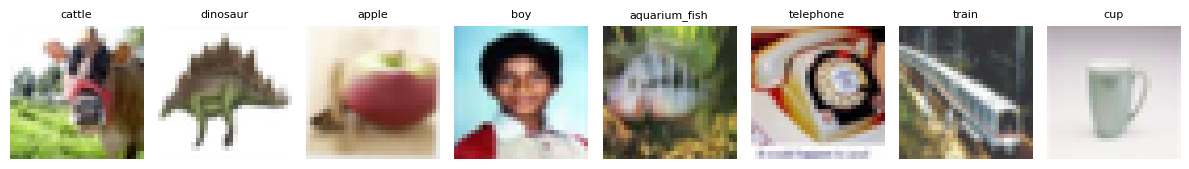

In [1]:
#N1: imports + threads + load CIFAR-100 (pickled files: meta, train, test), kept in colour

import os
N_THREADS = 6                                    # Baby-U: 12 cores, the GPU does the training (6 leaves room for a 2nd notebook)
os.environ["OMP_NUM_THREADS"] = str(N_THREADS)   # must be set BEFORE importing torch/numpy
os.environ["MKL_NUM_THREADS"] = str(N_THREADS)

import pickle, time, math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
torch.set_num_threads(N_THREADS)                 # PyTorch uses only these cores
print("threads:", torch.get_num_threads())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0), f"({torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GB)")
    torch.backends.cuda.matmul.allow_tf32 = True     # RTX 30xx: faster float32 matrix products, same results to ~3 digits
    torch.backends.cudnn.allow_tf32 = True
else:
    print("no GPU found: running on the CPU (much slower)")

CPU_SLOT = 1     # only used on the 64-core Fatbaby: 0 -> cores 0-15, 1 -> 16-31, ... (Baby-U skips this)
if (os.cpu_count() or 0) >= 64:
    os.sched_setaffinity(0, range(16 * CPU_SLOT, 16 * CPU_SLOT + 16))
    print(f"pinned to cores {16 * CPU_SLOT}-{16 * CPU_SLOT + 15}")

BASE = '/home/worker/Scaricati/cifar'   # CHANGE to the folder on Baby-U that holds meta, train, test

def unpickle(path):
    with open(path, 'rb') as f:
        return pickle.load(f, encoding='latin1')

meta  = unpickle(os.path.join(BASE, 'meta'))
train = unpickle(os.path.join(BASE, 'train'))
test  = unpickle(os.path.join(BASE, 'test'))
fine_names = meta['fine_label_names']            # 100 names, index = fine label

# each row = 1024 red + 1024 green + 1024 blue values -> keep colour: [N, 3, 32, 32] (no grayscale, no resizing)
x_train_all = np.asarray(train['data'], dtype=np.uint8).reshape(-1, 3, 32, 32)
y_train_all = np.array(train['fine_labels'])
x_test_all  = np.asarray(test['data'], dtype=np.uint8).reshape(-1, 3, 32, 32)
y_test_all  = np.array(test['fine_labels'])
print(f"train: {x_train_all.shape}   test: {x_test_all.shape}")

fig, axes = plt.subplots(1, 8, figsize=(12, 1.9))
for k in range(8):
    axes[k].imshow(x_train_all[k].transpose(1, 2, 0))
    axes[k].set_title(fine_names[y_train_all[k]], fontsize=8)
    axes[k].axis('off')
plt.tight_layout(); plt.show()

In [2]:
import sys, os, subprocess, torch
print("python used by this notebook:", sys.executable)
print("torch version:", torch.__version__, "| built for CUDA:", torch.version.cuda)
print("cuda available:", torch.cuda.is_available())
print("CUDA_VISIBLE_DEVICES =", os.environ.get("CUDA_VISIBLE_DEVICES"))
try:
    print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
except FileNotFoundError:
    print("nvidia-smi not found -> NVIDIA driver not installed (or not on PATH)")

python used by this notebook: /opt/miniconda3/bin/python
torch version: 2.8.0+cu128 | built for CUDA: 12.8
cuda available: True
CUDA_VISIBLE_DEVICES = None
Thu Nov  5 11:33:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 615.71.10              KMD Version: 615.71.10     CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3070 Ti     On  |   00000000:65:00.0 Off |                  N/A |
|  0%   45C    P8             27W /  290W |       4MiB /   8192MiB |      0%

In [3]:
#N2: defining 20 problems: the 20 CIFAR-100 superclasses, 5 fine classes each (same as the MLP notebooks)

SCRIPT_NAMES = ["P1_aquatic", "P2_fish", "P3_flowers", "P4_containers", "P5_produce",
                "P6_devices", "P7_furniture", "P8_insects", "P9_carnivores", "P10_outdoor_things",
                "P11_outdoor_scenes", "P12_omni_herbivores", "P13_medium_mammals", "P14_invertebrates", "P15_people",
                "P16_reptiles", "P17_small_mammals", "P18_trees", "P19_vehicles_1", "P20_vehicles_2"]

GROUP_CLASS_NAMES = [
    ["beaver", "dolphin", "otter", "seal", "whale"],                     # P1
    ["aquarium_fish", "flatfish", "ray", "shark", "trout"],              # P2
    ["orchid", "poppy", "rose", "sunflower", "tulip"],                   # P3
    ["bottle", "bowl", "can", "cup", "plate"],                           # P4
    ["apple", "mushroom", "orange", "pear", "sweet_pepper"],             # P5
    ["clock", "keyboard", "lamp", "telephone", "television"],            # P6
    ["bed", "chair", "couch", "table", "wardrobe"],                      # P7
    ["bee", "beetle", "butterfly", "caterpillar", "cockroach"],          # P8
    ["bear", "leopard", "lion", "tiger", "wolf"],                        # P9
    ["bridge", "castle", "house", "road", "skyscraper"],                 # P10
    ["cloud", "forest", "mountain", "plain", "sea"],                     # P11
    ["camel", "cattle", "chimpanzee", "elephant", "kangaroo"],           # P12
    ["fox", "porcupine", "possum", "raccoon", "skunk"],                  # P13
    ["crab", "lobster", "snail", "spider", "worm"],                      # P14
    ["baby", "boy", "girl", "man", "woman"],                             # P15
    ["crocodile", "dinosaur", "lizard", "snake", "turtle"],              # P16
    ["hamster", "mouse", "rabbit", "shrew", "squirrel"],                 # P17
    ["maple_tree", "oak_tree", "palm_tree", "pine_tree", "willow_tree"], # P18
    ["bicycle", "bus", "motorcycle", "pickup_truck", "train"],           # P19
    ["lawn_mower", "rocket", "streetcar", "tank", "tractor"],            # P20
]

name_to_fine = {n: i for i, n in enumerate(fine_names)}
GROUP_LABELS = [[name_to_fine[n] for n in grp] for grp in GROUP_CLASS_NAMES]
for name, names, labels in zip(SCRIPT_NAMES, GROUP_CLASS_NAMES, GROUP_LABELS):
    print(f"{name:20s}", list(zip(names, labels)))
print("\n20 problems, 5 classes each, all 100 CIFAR-100 fine classes used")

P1_aquatic           [('beaver', 4), ('dolphin', 30), ('otter', 55), ('seal', 72), ('whale', 95)]
P2_fish              [('aquarium_fish', 1), ('flatfish', 32), ('ray', 67), ('shark', 73), ('trout', 91)]
P3_flowers           [('orchid', 54), ('poppy', 62), ('rose', 70), ('sunflower', 82), ('tulip', 92)]
P4_containers        [('bottle', 9), ('bowl', 10), ('can', 16), ('cup', 28), ('plate', 61)]
P5_produce           [('apple', 0), ('mushroom', 51), ('orange', 53), ('pear', 57), ('sweet_pepper', 83)]
P6_devices           [('clock', 22), ('keyboard', 39), ('lamp', 40), ('telephone', 86), ('television', 87)]
P7_furniture         [('bed', 5), ('chair', 20), ('couch', 25), ('table', 84), ('wardrobe', 94)]
P8_insects           [('bee', 6), ('beetle', 7), ('butterfly', 14), ('caterpillar', 18), ('cockroach', 24)]
P9_carnivores        [('bear', 3), ('leopard', 42), ('lion', 43), ('tiger', 88), ('wolf', 97)]
P10_outdoor_things   [('bridge', 12), ('castle', 17), ('house', 37), ('road', 68), ('skysc

In [4]:
#N3: building 20 datasets: colour 3x32x32, standardized per problem and per colour channel
#    every problem has THREE sets of images:
#      training images  2,250 (450 per class)  the network learns from these
#      validation images  250 (50 per class, taken from the 500 training images of each class)
#                             -> early stopping: when to stop a run; the network never learns from them
#      test images        500 (100 per class)  tested once per run, with its best weights (N6); never for a decision

VAL_PER_CLASS = 50

rng = np.random.default_rng(0)    # fixed: the same validation images as the TUNING = True runs of the earlier notebooks
X_tr, Y_tr, X_val, Y_val, X_te, Y_te = [], [], [], [], [], []
for m in range(20):
    xs_tr, ys_tr, xs_val, ys_val, xs_te, ys_te = [], [], [], [], [], []
    for new_label, old_label in enumerate(GROUP_LABELS[m]):          # labels 0-4 = position in the group list
        tr = x_train_all[y_train_all == old_label]                   # 500 training images of this class
        te = x_test_all[y_test_all == old_label]                     # 100 test images of this class
        perm = rng.permutation(len(tr))
        va, tr = tr[perm[:VAL_PER_CLASS]], tr[perm[VAL_PER_CLASS:]]   # 50 validation, 450 to learn from
        xs_tr.append(tr); ys_tr.append(np.full(len(tr), new_label))
        xs_val.append(va); ys_val.append(np.full(len(va), new_label))
        xs_te.append(te); ys_te.append(np.full(len(te), new_label))
    x_tr = torch.tensor(np.concatenate(xs_tr), dtype=torch.float32)  # [2250, 3, 32, 32]
    x_val = torch.tensor(np.concatenate(xs_val), dtype=torch.float32)  # [250, 3, 32, 32]
    x_te = torch.tensor(np.concatenate(xs_te), dtype=torch.float32)  # [500, 3, 32, 32]
    mean = x_tr.mean(dim=(0, 2, 3), keepdim=True)                    # one mean and std per colour channel,
    std  = x_tr.std(dim=(0, 2, 3), keepdim=True)                     # from this problem's training images only
    X_tr.append((x_tr - mean) / std); Y_tr.append(torch.tensor(np.concatenate(ys_tr), dtype=torch.long))
    X_val.append((x_val - mean) / std); Y_val.append(torch.tensor(np.concatenate(ys_val), dtype=torch.long))
    X_te.append((x_te - mean) / std); Y_te.append(torch.tensor(np.concatenate(ys_te), dtype=torch.long))
    print(f"{SCRIPT_NAMES[m]:20s} train {len(x_tr):5d}  validation {len(x_val):4d}  test {len(x_te):4d}  "
          f"channel means {[round(v, 1) for v in mean.flatten().tolist()]}")

X_tr, Y_tr   = torch.stack(X_tr), torch.stack(Y_tr)     # [20, 2250, 3, 32, 32] and [20, 2250]  (every problem has the same size)
X_val, Y_val = torch.stack(X_val), torch.stack(Y_val)   # [20, 250, 3, 32, 32]  and [20, 250]
X_te, Y_te   = torch.stack(X_te), torch.stack(Y_te)     # [20, 500, 3, 32, 32]  and [20, 500]
print(f"\nX_tr {tuple(X_tr.shape)}   X_val {tuple(X_val.shape)} (validation)   X_te {tuple(X_te.shape)} (test)")

P1_aquatic           train  2250  validation  250  test  500  channel means [108.1, 122.2, 127.2]
P2_fish              train  2250  validation  250  test  500  channel means [106.2, 117.8, 116.6]
P3_flowers           train  2250  validation  250  test  500  channel means [133.4, 104.0, 78.0]
P4_containers        train  2250  validation  250  test  500  channel means [148.5, 139.3, 130.4]
P5_produce           train  2250  validation  250  test  500  channel means [153.0, 125.4, 91.9]
P6_devices           train  2250  validation  250  test  500  channel means [142.2, 136.9, 134.0]
P7_furniture         train  2250  validation  250  test  500  channel means [155.4, 137.4, 124.5]
P8_insects           train  2250  validation  250  test  500  channel means [141.8, 136.9, 109.6]
P9_carnivores        train  2250  validation  250  test  500  channel means [120.2, 111.9, 94.7]
P10_outdoor_things   train  2250  validation  250  test  500  channel means [123.7, 130.0, 130.4]
P11_outdoor_scenes   tr

In [5]:
#N4: settings, batches, augmentation and the ViT (the same code as Experiments 1 and 2), and the a values

DEVICE        = 'cuda' if torch.cuda.is_available() else 'cpu'
NUM_PROBLEMS  = 20
CLASSES_PER   = 5

IMG, PATCH, CH = 32, 4, 3
N_PATCHES     = (IMG // PATCH) ** 2        # 64 patches per image (8 x 8)
PATCH_DIM     = PATCH * PATCH * CH         # 48 numbers per patch (4 x 4 x 3)
TOKENS        = N_PATCHES + 1              # 64 patches + 1 CLS token = 65
D             = 128                        # numbers per token
DEPTH         = 6                          # encoder blocks
HEADS         = 4                          # 4 heads x 32 dims
MLP_DIM       = 256                        # MLP inside each block: 128 -> 256 -> 128

BATCH_SIZE    = 32                         # per problem per step -> 640 images per step
LEARNING_RATE = 1e-4                       # the best learning rate of Experiments 1 and 2, the same for every a
A_VALUES      = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]   # run one after the other in N6
WEIGHT_DECAY  = 0.05
NUM_EPOCHS    = 100                        # at most 100 epochs: early stopping can end a run sooner
PATIENCE      = 10                         # early stopping: stop when the validation accuracy has not improved for 10 epochs in a row
WARMUP_EPOCHS = 5
N_RUNS        = 50                         # runs for EACH a: 10 a values x 10 runs = 100 runs, about 10-11 h
                                           # (can be raised later, e.g. to 30: N6 keeps the finished runs and adds the rest)
PRINT_EVERY_EPOCHS = 10                    # print one line every 10 epochs (the early-stopping check itself runs after EVERY epoch)
RESULTS_FILE  = 'compound_a_values_lr1e-4_early_stopping.json'   # N6 saves every finished run here, N7 reads it
N_TRAIN       = X_tr.shape[1]                       # 2,250 per problem (50 per class are held out)
STEPS_PER_EPOCH = N_TRAIN // BATCH_SIZE             # 70: one pass over each problem
TOTAL_STEPS   = NUM_EPOCHS * STEPS_PER_EPOCH
WARMUP_STEPS  = WARMUP_EPOCHS * STEPS_PER_EPOCH

X_tr, Y_tr, X_te, Y_te = X_tr.to(DEVICE), Y_tr.to(DEVICE), X_te.to(DEVICE), Y_te.to(DEVICE)   # ~0.7 GB, stays on the GPU
X_val, Y_val = X_val.to(DEVICE), Y_val.to(DEVICE)

USE_AMP = DEVICE == 'cuda'       # bfloat16 mixed precision on the GPU tensor cores (~2x faster); the weight sets stay float32

def amp():
    return torch.autocast(device_type=DEVICE, dtype=torch.bfloat16, enabled=USE_AMP)

# every weight tensor of one ViT: [out, in]  (no biases; LayerNorm has no learnable gain or bias)
SHAPES = {'patch': (D, PATCH_DIM), 'cls': (D,), 'pos': (TOKENS, D), 'head': (CLASSES_PER, D)}
for l in range(DEPTH):
    SHAPES[f'b{l}.qkv']  = (3 * D, D)       # Q, K, V together: 128 -> 384
    SHAPES[f'b{l}.proj'] = (D, D)           # joins the 4 heads: 128 -> 128
    SHAPES[f'b{l}.fc1']  = (MLP_DIM, D)     # 128 -> 256
    SHAPES[f'b{l}.fc2']  = (D, MLP_DIM)     # 256 -> 128
PARAMS_PER_VIT = sum(math.prod(s) for s in SHAPES.values())      # 801,664


def new_weight_sets(n_sets):
    """n_sets complete copies of every ViT tensor, stored as [n_sets, out, in]; small random start (std 0.02)"""
    G = {}
    for k, s in SHAPES.items():
        t = torch.empty(n_sets, *s, device=DEVICE)
        nn.init.trunc_normal_(t, std=0.02, a=-0.04, b=0.04)
        G[k] = nn.Parameter(t)
    return G


def lr_factor(step):
    """linear warmup for WARMUP_EPOCHS, then cosine decay to 0 at the last step"""
    if step < WARMUP_STEPS:
        return (step + 1) / WARMUP_STEPS
    p = (step - WARMUP_STEPS) / max(1, TOTAL_STEPS - WARMUP_STEPS)
    return 0.5 * (1 + math.cos(math.pi * p))


class Batches:
    """one batch of 32 per problem per step; each problem's images are reshuffled after every full pass"""
    def __init__(self):
        self.pos = N_TRAIN
    def next(self):
        if self.pos + BATCH_SIZE > N_TRAIN:
            self.perm = torch.argsort(torch.rand(NUM_PROBLEMS, N_TRAIN, device=DEVICE), dim=1)
            self.pos = 0
        idx = self.perm[:, self.pos:self.pos + BATCH_SIZE]                 # [20, 32]
        self.pos += BATCH_SIZE
        rows = torch.arange(NUM_PROBLEMS, device=DEVICE)[:, None]
        return X_tr[rows, idx], Y_tr[rows, idx]                            # [20, 32, 3, 32, 32], [20, 32]


def augment(x):
    """training only: random crop (pad 4, crop 32x32) + random horizontal flip, a different one for every image"""
    M, Bsz = x.shape[:2]
    x = x.reshape(M * Bsz, CH, IMG, IMG)
    xp = F.pad(x, (4, 4, 4, 4)).permute(0, 2, 3, 1)                       # [N, 40, 40, 3]; padding 0 = channel mean
    N = xp.shape[0]
    ox = torch.randint(0, 9, (N,), device=x.device)
    oy = torch.randint(0, 9, (N,), device=x.device)
    ar = torch.arange(IMG, device=x.device)
    rows = (oy[:, None] + ar)[:, :, None]                                  # [N, 32, 1]
    cols = (ox[:, None] + ar)[:, None, :]                                  # [N, 1, 32]
    out = xp[torch.arange(N, device=x.device)[:, None, None], rows, cols].permute(0, 3, 1, 2)   # [N, 3, 32, 32]
    flip = torch.rand(N, device=x.device) < 0.5
    out = torch.where(flip[:, None, None, None], out.flip(3), out)
    return out.reshape(M, Bsz, CH, IMG, IMG)


def vit_forward(x, W):
    """x: [M, B, 3, 32, 32] images of M problems; W: every tensor as [M, out, in] = one ViT per problem.
       returns [M, B, 5] scores. All M problems run at the same time, each with its own weights."""
    M, Bsz = x.shape[:2]
    p = x.unfold(3, PATCH, PATCH).unfold(4, PATCH, PATCH)                  # [M, B, 3, 8, 8, 4, 4]
    p = p.permute(0, 1, 3, 4, 2, 5, 6).reshape(M, Bsz, N_PATCHES, PATCH_DIM)   # [M, B, 64, 48]
    t = torch.einsum('mbpc,mdc->mbpd', p, W['patch'])                     # [M, B, 64, 128]
    cls = W['cls'][:, None, None, :].expand(M, Bsz, 1, D)
    t = torch.cat([cls, t], dim=2) + W['pos'][:, None]                     # [M, B, 65, 128]
    for l in range(DEPTH):
        h = F.layer_norm(t, (D,))
        qkv = torch.einsum('mbtd,med->mbte', h, W[f'b{l}.qkv'])            # [M, B, 65, 384]
        qkv = qkv.reshape(M * Bsz, TOKENS, 3, HEADS, D // HEADS).permute(2, 0, 3, 1, 4)   # 3 x [M*B, 4, 65, 32]
        att = F.scaled_dot_product_attention(qkv[0], qkv[1], qkv[2])        # softmax(Q K^T / sqrt(32)) V
        att = att.transpose(1, 2).reshape(M, Bsz, TOKENS, D)               # join the 4 heads: [M, B, 65, 128]
        t = t + torch.einsum('mbtd,med->mbte', att, W[f'b{l}.proj'])       # residual 1
        h = F.layer_norm(t, (D,))
        h = F.gelu(torch.einsum('mbtd,med->mbte', h, W[f'b{l}.fc1']))      # [M, B, 65, 256]
        t = t + torch.einsum('mbte,mde->mbtd', h, W[f'b{l}.fc2'])          # residual 2
    c = F.layer_norm(t[:, :, 0], (D,))                                     # CLS token: [M, B, 128]
    return torch.einsum('mbd,mcd->mbc', c, W['head'])                      # [M, B, 5]


def problem_losses(out, y):
    """mean cross-entropy of each problem's batch: [M]"""
    return F.cross_entropy(out.reshape(-1, CLASSES_PER), y.reshape(-1), reduction='none').reshape(out.shape[0], -1).mean(1)


@torch.no_grad()
def evaluate(G, X, Y, chunk=100):
    """accuracy per problem (each problem with its own weights) and the average loss per problem, on the images X
       with labels Y:  X_val, Y_val = the validation images,  X_te, Y_te = the test images"""
    W = build_weights(G)
    n = X.shape[1]
    correct = torch.zeros(NUM_PROBLEMS, device=DEVICE)
    loss = torch.zeros(NUM_PROBLEMS, device=DEVICE)
    for s in range(0, n, chunk):
        y = Y[:, s:s + chunk]
        with amp():
            out = vit_forward(X[:, s:s + chunk], W)
            loss += problem_losses(out, y).float() * y.shape[1]
        correct += (out.argmax(-1) == y).sum(1)
    return (correct / n * 100).tolist(), (loss / n).mean().item()


# ---------------------------------------------------------------- COMPOUND: 6 G sets, each problem uses its own 3 + a x the other 3
NUM_SETS = 6

# 1 = one of the problem's OWN 3 G sets, 0 = one of the other 3: the same 20 combinations as in Experiments 1 and 2
B_PATTERN = torch.tensor([
    [1,1,1,0,0,0],   # P1
    [1,1,0,1,0,0],   # P2
    [1,1,0,0,1,0],   # P3
    [1,1,0,0,0,1],   # P4
    [1,0,1,1,0,0],   # P5
    [1,0,1,0,1,0],   # P6
    [1,0,1,0,0,1],   # P7
    [1,0,0,1,1,0],   # P8
    [1,0,0,1,0,1],   # P9
    [1,0,0,0,1,1],   # P10
    [0,1,1,1,0,0],   # P11
    [0,1,1,0,1,0],   # P12
    [0,1,1,0,0,1],   # P13
    [0,1,0,1,1,0],   # P14
    [0,1,0,1,0,1],   # P15
    [0,1,0,0,1,1],   # P16
    [0,0,1,1,1,0],   # P17
    [0,0,1,1,0,1],   # P18
    [0,0,1,0,1,1],   # P19
    [0,0,0,1,1,1],   # P20
], dtype=torch.float32, device=DEVICE)

def set_a(value):
    """sets a for the runs that follow (N6 calls it once for every value in A_VALUES):
       b table: 1 for the problem's own 3 G sets, a for the other 3    (a = 0: original compound, a = 1: no switching)
       scale:   sqrt(3 + 3a^2), so the built weights start at the same size as one normal ViT"""
    global a, B_CONFIGS, SCALE
    a = value
    B_CONFIGS = B_PATTERN + a * (1 - B_PATTERN)          # [20, 6]: the b table for this a
    SCALE = (3 + 3 * a ** 2) ** 0.5

set_a(A_VALUES[0])

def g_set_lr(lr):
    """the learning rate AdamW uses for the G sets, with the same rule as before: Adam moves each G set by ~lr;
       this makes a = 1 train exactly like b = [1,0,...].   lr 1e-4: a=0.1 -> 5.27e-5, a=0.5 -> 4.30e-5, a=1 -> 4.08e-5"""
    return lr * SCALE / (3 + 3 * a)

def build_weights(G):
    """every tensor of problem m's ViT:  W[m] = sum_n b[m,n] * G[n] / scale   (all 20 problems in one einsum)"""
    return {k: torch.einsum('mn,n...->m...', B_CONFIGS, g)/SCALE  for k, g in G.items()}

print(f"Device: {DEVICE}   mixed precision (bfloat16): {USE_AMP}")
print(f"ViT: {N_PATCHES} patches + CLS = {TOKENS} tokens of {D}, {DEPTH} blocks, {HEADS} heads, MLP {MLP_DIM} "
      f"-> {PARAMS_PER_VIT:,} weights per ViT")
print(f"Compound: {NUM_SETS} G sets x {PARAMS_PER_VIT:,} = {NUM_SETS * PARAMS_PER_VIT:,} parameters   learning rate {LEARNING_RATE:.0e}")
print(f"{N_RUNS} runs for each of the {len(A_VALUES)} a values, one after the other: {N_RUNS * len(A_VALUES)} runs")
print(f"\n{'a':>5} {'scale':>7} {'G-set lr':>10} {'start std':>10}    (start std: one built 128 x 128 table; one normal ViT: ~0.0176)")
for v in A_VALUES:
    set_a(v)
    t = torch.empty(NUM_SETS, D, D, device=DEVICE)
    nn.init.trunc_normal_(t, std=0.02, a=-0.04, b=0.04)
    w = torch.einsum('mn,nij->mij', B_CONFIGS, t) / SCALE
    print(f"{v:5.1f} {SCALE:7.3f} {g_set_lr(LEARNING_RATE):10.2e} {w[0].std().item():10.4f}")
set_a(A_VALUES[0])
print()
print(f"Epochs: at most {NUM_EPOCHS}, early stopping with patience {PATIENCE}   Steps/epoch: {STEPS_PER_EPOCH}  Warmup epochs: {WARMUP_EPOCHS}")
print(f"All losses = avg CE per problem  (5-way random guess = ln5 = {np.log(5):.3f})")

Device: cuda   mixed precision (bfloat16): True
ViT: 64 patches + CLS = 65 tokens of 128, 6 blocks, 4 heads, MLP 256 -> 801,664 weights per ViT
Compound: 6 G sets x 801,664 = 4,809,984 parameters   learning rate 1e-04
50 runs for each of the 10 a values, one after the other: 500 runs

    a   scale   G-set lr  start std    (start std: one built 128 x 128 table; one normal ViT: ~0.0176)
  0.1   1.741   5.27e-05     0.0174
  0.2   1.766   4.91e-05     0.0176
  0.3   1.808   4.64e-05     0.0177
  0.4   1.865   4.44e-05     0.0177
  0.5   1.936   4.30e-05     0.0176
  0.6   2.020   4.21e-05     0.0177
  0.7   2.114   4.15e-05     0.0175
  0.8   2.218   4.11e-05     0.0175
  0.9   2.330   4.09e-05     0.0176
  1.0   2.449   4.08e-05     0.0178

Epochs: at most 100, early stopping with patience 10   Steps/epoch: 70  Warmup epochs: 5
All losses = avg CE per problem  (5-way random guess = ln5 = 1.609)


In [6]:
#N5: ONE TRAINING RUN WITH EARLY STOPPING (N6 uses it for every run; the same code as Experiment 2)
# every step: one batch of 32 from each of the 20 problems -> each problem's ViT (built from its 3 G sets)
#             -> 20 losses added -> one backward pass -> one AdamW step on all weight sets
# after every epoch: accuracy on the validation images (average over the 20 problems)
#   better than ever before -> save a copy of the weights, counter back to 0
#   not better              -> counter + 1; when the counter reaches PATIENCE, the run stops
# at the end: back to the saved best weights

HEADER = (f"{'a':>8} {'Run':>4} {'Ep':>4} | {'Tr loss':>8} {'Val loss':>8} | {'Tr acc':>7} {'Val acc':>7} | "
          + " ".join(f"{'P'+str(i+1):>5}" for i in range(20)))


def train_one_run(LR_G, label, use_test=False, show_estimate=False):
    """trains one network from new random weights with the AdamW learning rate LR_G and early stopping.
       returns the numbers of the BEST weights (the epoch with the highest validation accuracy).
       use_test=True: the best weights are then tested once on the test images (N6 always does this)."""
    G = new_weight_sets(NUM_SETS)
    optimizer = torch.optim.AdamW(G.values(), lr=LR_G, betas=(0.9, 0.999), weight_decay=WEIGHT_DECAY)
    batches   = Batches()
    step_global = 0
    best_acc, best_epoch, waited = -1.0, 0, 0       # best validation accuracy so far, its epoch, epochs without improvement

    for epoch in range(NUM_EPOCHS):
        t_ep = time.time()
        epoch_loss = 0.0
        tr_correct = tr_total = 0
        for step in range(STEPS_PER_EPOCH):
            for group in optimizer.param_groups:
                group['lr'] = LR_G * lr_factor(step_global)
            step_global += 1

            x, y = batches.next()                          # [20, 32, 3, 32, 32], [20, 32]
            x = augment(x)
            with amp():
                out = vit_forward(x, build_weights(G))     # [20, 32, 5]
                total_loss = problem_losses(out, y).sum()  # plain sum of the 20 problem losses

            optimizer.zero_grad(set_to_none=True)
            total_loss.backward()
            optimizer.step()

            epoch_loss += total_loss.item()
            tr_correct += (out.argmax(-1) == y).sum().item()
            tr_total   += y.numel()

        avg_tr = epoch_loss / STEPS_PER_EPOCH / NUM_PROBLEMS
        tr_acc = tr_correct / tr_total * 100

        if show_estimate and epoch == 0:
            sec = time.time() - t_ep
            print(f"  first epoch took {sec:.0f}s -> at most about {sec * NUM_EPOCHS / 60:.0f} min per run (less when it stops early)")

        # ---- early stopping: check the validation images after every epoch
        val_accs, val_loss = evaluate(G, X_val, Y_val)
        if np.mean(val_accs) > best_acc:                                       # better than ever before
            best_acc, best_epoch, waited = np.mean(val_accs), epoch + 1, 0
            best_G = {name: w.detach().clone() for name, w in G.items()}     # save a copy of the weights
            best = {'val_accs': val_accs, 'val_loss': val_loss, 'tr_acc': tr_acc, 'tr_loss': avg_tr}
        else:                                                                 # not better
            waited += 1
        stop = waited >= PATIENCE

        if (epoch + 1) % PRINT_EVERY_EPOCHS == 0 or stop:
            print(f"{label} {epoch+1:4d} | {avg_tr:8.4f} {val_loss:8.4f} | {tr_acc:6.2f}% {np.mean(val_accs):6.2f}% | "
                  + " ".join(f"{acc:5.1f}" for acc in val_accs))
        if stop:
            print(f"  early stop after epoch {epoch+1}: no better validation accuracy for {PATIENCE} epochs "
                  f"-> back to the weights of epoch {best_epoch}")
            break

    with torch.no_grad():                                                     # back to the best weights
        for name in G:
            G[name].copy_(best_G[name])
    best.update(best_epoch=best_epoch, stop_epoch=epoch + 1)
    if use_test:
        best['te_accs'], best['te_loss'] = evaluate(G, X_te, Y_te)            # the test images: only here, only once
    return best

print("train_one_run is ready")

train_one_run is ready


In [7]:
#N6: RUNS FOR EVERY a, ONE AFTER THE OTHER: compound ViT, learning rate 1e-4, early stopping
#    for every a in A_VALUES: N_RUNS runs, each from new random weights. Each run stops when its validation accuracy has
#    not improved for 10 epochs, goes back to its best weights and tests them ONCE on the test images.
#    Every a gets the same settings and the same number of runs; only a (and with it the scale and the G-set lr) changes.
#    Every finished run is saved at once in RESULTS_FILE. If the notebook stops (restart, power cut): run N1 to N5 again
#    and then this cell: it continues where it stopped; the finished runs are kept and not repeated.

import json

def save_results():
    tmp = RESULTS_FILE + '.tmp'
    with open(tmp, 'w') as f:
        json.dump({'learning_rate': LEARNING_RATE, 'patience': PATIENCE, 'max_epochs': NUM_EPOCHS, 'runs': results}, f)
    os.replace(tmp, RESULTS_FILE)               # the old file is replaced only when the new one is complete

results = {}                                    # a as text ('0.1', '0.2', ...) -> list of runs (numbers of each run's best weights)
if os.path.exists(RESULTS_FILE):
    saved = json.load(open(RESULTS_FILE))
    if (saved['learning_rate'], saved['patience'], saved['max_epochs']) != (LEARNING_RATE, PATIENCE, NUM_EPOCHS):
        raise ValueError(f"{RESULTS_FILE} was made with other settings: rename it (to keep it) or delete it, then run N6 again")
    results = saved['runs']
    print(f"continuing from {RESULTS_FILE}: " + ", ".join(f"a {k}: {len(v)} runs" for k, v in results.items()))

todo = sum(max(0, N_RUNS - len(results.get(f'{v:.1f}', []))) for v in A_VALUES)
print(f"COMPOUND ViT on CIFAR-100 (20 problems x 5 classes), learning rate {LEARNING_RATE:.0e}, early stopping with "
      f"patience {PATIENCE}: {len(A_VALUES)} a values x {N_RUNS} runs, {todo} runs still to do")
print("Val = validation images (250 per problem): only for early stopping;  TEST = test images, once per run")
print(HEADER)
print("-" * len(HEADER))
t0, done = time.time(), 0

for v in A_VALUES:
    key = f'{v:.1f}'
    runs = results.setdefault(key, [])
    if len(runs) >= N_RUNS:
        print(f"\n=== a = {key}: {len(runs)} runs already done, skipped ===")
        continue
    set_a(v)
    LR_G = g_set_lr(LEARNING_RATE)              # the learning rate AdamW uses for the G sets at this a
    print(f"\n=== a = {key}   scale {SCALE:.3f}   AdamW lr for the G sets {LR_G:.2e} ===")
    for run in range(len(runs), N_RUNS):
        r = train_one_run(LR_G, f"{key:>8} {run+1:4d}", use_test=True, show_estimate=(done == 0))
        r['a'] = v
        runs.append(r)
        save_results()
        done += 1
        took = time.time() - t0
        print(f"  → a {key}  run {run+1}  best epoch {r['best_epoch']} (stopped after {r['stop_epoch']})  "
              f"validation acc {np.mean(r['val_accs']):.2f}%  TEST acc {np.mean(r['te_accs']):.2f}%  test loss {r['te_loss']:.4f}  "
              f"[{took / 3600:.1f} h, about {took / done * (todo - done) / 3600:.1f} h left]\n")
    te = [np.mean(r['te_accs']) for r in runs]
    print(f"  a {key} DONE ({len(runs)} runs):  test acc {np.mean(te):.2f}% ± {np.std(te):.2f}%  |  "
          f"validation acc {np.mean([np.mean(r['val_accs']) for r in runs]):.2f}%  |  "
          f"best epoch {np.mean([r['best_epoch'] for r in runs]):.0f} on average")

print(f"\nall {len(A_VALUES)} a values done: {N_RUNS} runs each, saved in {RESULTS_FILE}")


COMPOUND ViT on CIFAR-100 (20 problems x 5 classes), learning rate 1e-04, early stopping with patience 10: 10 a values x 50 runs, 500 runs still to do
Val = validation images (250 per problem): only for early stopping;  TEST = test images, once per run
       a  Run   Ep |  Tr loss Val loss |  Tr acc Val acc |    P1    P2    P3    P4    P5    P6    P7    P8    P9   P10   P11   P12   P13   P14   P15   P16   P17   P18   P19   P20
----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

=== a = 0.1   scale 1.741   AdamW lr for the G sets 5.27e-05 ===
  first epoch took 2s -> at most about 4 min per run (less when it stops early)
     0.1    1   10 |   1.1769   1.1831 |  51.87%  52.18% |  46.8  68.4  60.8  37.2  65.6  47.2  50.0  47.2  54.4  60.0  66.8  54.8  50.8  50.0  34.0  44.8  46.0  47.6  48.8  62.4
     0.1    1   20 |   0.9990   1.0472 |  60.47%  58.10% |  54.0

COMPOUND ViT, learning rate 1e-04, early stopping (patience 10): results for every a
test acc: the best weights of each run, tested once on the 500 test images per problem; mean ± std over the runs
   a  scale  G-set lr  runs |         test acc |   validation acc | train acc |    best epoch |       stopped
-------------------------------------------------------------------------------------------------------------
 0.0  1.732  5.77e-05    50 |  65.23% ±  0.59% |   from Experiment 2 (not run here), for comparison
 0.1  1.741  5.27e-05    50 |  64.84% ±  0.53% |  64.93% ±  0.47% |    75.71% |   62 ( 35- 85) |   72 ( 45- 95)
 0.2  1.766  4.91e-05    50 |  64.50% ±  0.55% |  64.60% ±  0.55% |    75.43% |   59 ( 32- 80) |   69 ( 42- 90)
 0.3  1.808  4.64e-05    50 |  64.13% ±  0.60% |  64.33% ±  0.61% |    75.75% |   60 ( 28- 85) |   70 ( 38- 95)
 0.4  1.865  4.44e-05    50 |  63.85% ±  0.56% |  63.96% ±  0.48% |    74.94% |   57 ( 33- 78) |   67 ( 43- 88)
 0.5  1.936  4.30e-05    50 |  63.

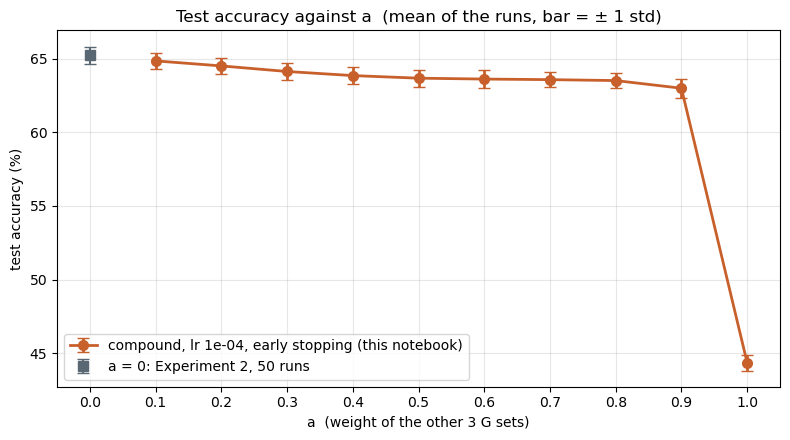

saved the plot: compound_a_values_lr1e-4_early_stopping.png


In [8]:
#N7: RESULTS FOR EVERY a: one line per a, the test accuracy of every problem, and a plot of the test accuracy against a
#    it reads RESULTS_FILE, so it also works after a restart (run N1 and N4 first) and shows the a values finished so far

import json
runs_by_a = json.load(open(RESULTS_FILE))['runs']
A_DONE = [k for k in sorted(runs_by_a, key=float) if runs_by_a[k]]
A0 = (65.23, 0.59, 50)     # a = 0 with the same settings (lr 1e-4, early stopping): Experiment 2, 50 final runs

def a_numbers(k):
    rs = runs_by_a[k]
    v = float(k)
    scale = (3 + 3 * v ** 2) ** 0.5
    return dict(runs=len(rs), scale=scale, g_lr=LEARNING_RATE * scale / (3 + 3 * v),
                te=[np.mean(r['te_accs']) for r in rs], val=[np.mean(r['val_accs']) for r in rs],
                tr=[r['tr_acc'] for r in rs], best=[r['best_epoch'] for r in rs], stop=[r['stop_epoch'] for r in rs],
                per_problem=np.mean([r['te_accs'] for r in rs], axis=0))

print(f"COMPOUND ViT, learning rate {LEARNING_RATE:.0e}, early stopping (patience {PATIENCE}): results for every a")
print("test acc: the best weights of each run, tested once on the 500 test images per problem; mean ± std over the runs")
header = (f"{'a':>4} {'scale':>6} {'G-set lr':>9} {'runs':>5} | {'test acc':>16} | {'validation acc':>16} | "
          f"{'train acc':>9} | {'best epoch':>13} | {'stopped':>13}")
print(header)
print("-" * len(header))
print(f"{'0.0':>4} {3 ** 0.5:6.3f} {LEARNING_RATE / 3 ** 0.5:9.2e} {A0[2]:5d} | {A0[0]:6.2f}% ± {A0[1]:5.2f}% |"
      "   from Experiment 2 (not run here), for comparison")
for k in A_DONE:
    n = a_numbers(k)
    print(f"{k:>4} {n['scale']:6.3f} {n['g_lr']:9.2e} {n['runs']:5d} | "
          f"{np.mean(n['te']):6.2f}% ± {np.std(n['te']):5.2f}% | {np.mean(n['val']):6.2f}% ± {np.std(n['val']):5.2f}% | "
          f"{np.mean(n['tr']):8.2f}% | {np.mean(n['best']):4.0f} ({min(n['best']):3d}-{max(n['best']):3d}) | "
          f"{np.mean(n['stop']):4.0f} ({min(n['stop']):3d}-{max(n['stop']):3d})")

print("\ntest accuracy of every problem (mean of the runs)")
print(f"{'a':>4} " + " ".join(f"{'P' + str(i + 1):>5}" for i in range(NUM_PROBLEMS)))
for k in A_DONE:
    print(f"{k:>4} " + " ".join(f"{x:5.1f}" for x in a_numbers(k)['per_problem']))

fig, ax = plt.subplots(figsize=(8, 4.5))
xs = [float(k) for k in A_DONE]
te_mean = [np.mean(a_numbers(k)['te']) for k in A_DONE]
te_std  = [np.std(a_numbers(k)['te']) for k in A_DONE]
ax.errorbar(xs, te_mean, yerr=te_std, color='#C8602C', lw=2, marker='o', ms=7, capsize=4,
            label=f'compound, lr {LEARNING_RATE:.0e}, early stopping (this notebook)')
ax.errorbar([0.0], [A0[0]], yerr=[A0[1]], color='#5A6874', marker='s', ms=7, capsize=4, ls='none',
            label='a = 0: Experiment 2, 50 runs')
ax.set_xticks([0.0] + xs)
ax.set_xticklabels([f'{x:.1f}' for x in [0.0] + xs])
ax.set_xlabel('a  (weight of the other 3 G sets)')
ax.set_ylabel('test accuracy (%)')
ax.set_title('Test accuracy against a  (mean of the runs, bar = ± 1 std)')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig('compound_a_values_lr1e-4_early_stopping.png', dpi=150)
plt.show()
print("saved the plot: compound_a_values_lr1e-4_early_stopping.png")
